In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
df_raw = pd.read_csv('../data/data.csv', encoding='ISO-8859-1')

print(df_raw.info())
df_raw.head()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB
None


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [10]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10,6]

In [11]:
df_clean = df_raw.dropna(subset=['CustomerID']).copy()
df_clean['CustomerId'] = df_clean['CustomerID'].astype(int)

df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

df_clean = df_clean[df_clean['UnitPrice'] > 0]

service_codes = ['POST', 'D', 'M', 'DOT', 'BANK CHARGES', 'CRUK']
df_clean = df_clean[~df_clean['StockCode'].isin(service_codes)]

df_clean['TotalAmount'] = df_clean['Quantity'] * df_clean['UnitPrice']

print(f"Строк после очистки ; {df_clean.shape[0]}")

Строк после очистки ; 405013


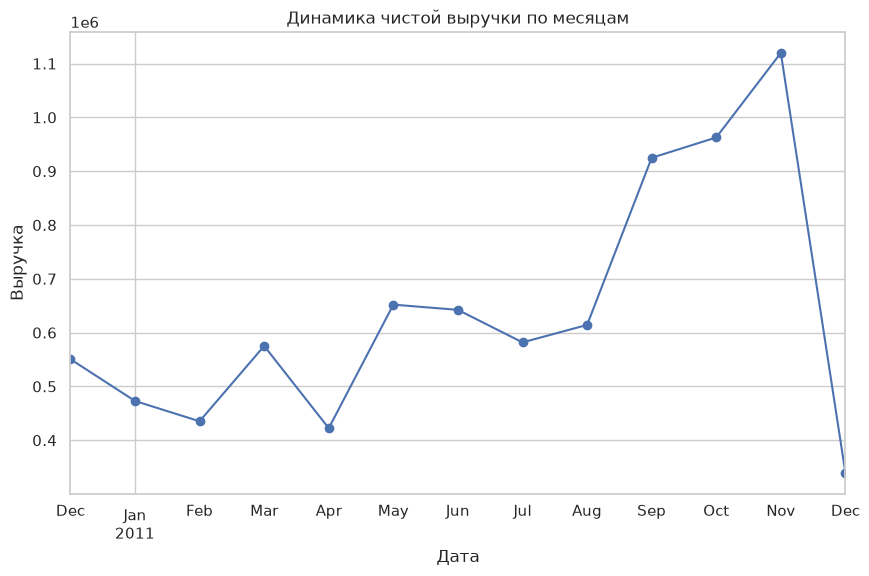

In [12]:
monthly_sales = df_clean.set_index('InvoiceDate').resample('ME')['TotalAmount'].sum()

monthly_sales.plot(kind='line', marker='o', color='b')
plt.title('Динамика чистой выручки по месяцам')
plt.xlabel('Дата')
plt.ylabel('Выручка')
plt.show()

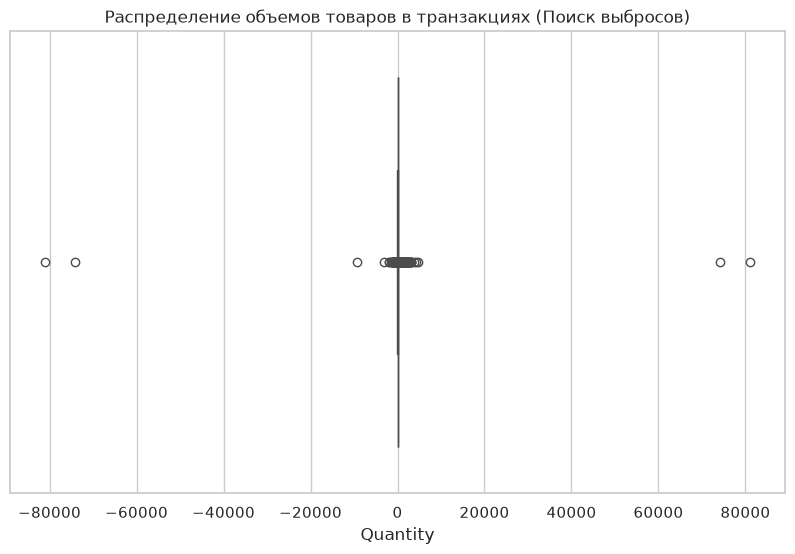

In [13]:
sns.boxplot(x=df_clean['Quantity'])

plt.title('Распределение объемов товаров в транзакциях (Поиск выбросов)')
plt.show()


In [14]:
today_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby('CustomerID').agg({
  #Прописать Recency, Frequency, Monetary 
    # Recency: из сегодняшней даты вычитаем дату последней покупки и берем чистые дни
    'InvoiceDate': lambda x: (today_date - x.max()).days,
    # Frequency: считаем количество УНИКАЛЬНЫХ инвойсов (чеков)
    'InvoiceNo': 'nunique',
    # Monetary: складываем суммы всех позиций (возвраты вычтутся сами)
    'TotalAmount': 'sum' 
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

rfm = rfm[rfm['Monetary'] > 0]

print(f"Итого уникальных клиентов в витрине : {rfm.shape[0]}")
rfm.head()

Итого уникальных клиентов в витрине : 4325


,Recency,Frequency,Monetary
CustomerID,,,
12347.0,2,7,4310.00
12348.0,75,4,1437.24
12349.0,19,1,1457.55
12350.0,310,1,294.40
12352.0,36,8,1265.41


In [ ]:
#анализ распределения метрик 